# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [3]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


In [4]:
cells['experiment'].value_counts()

experiment
untreated      5844
docetaxel      4707
osimertinib    4419
Name: count, dtype: int64

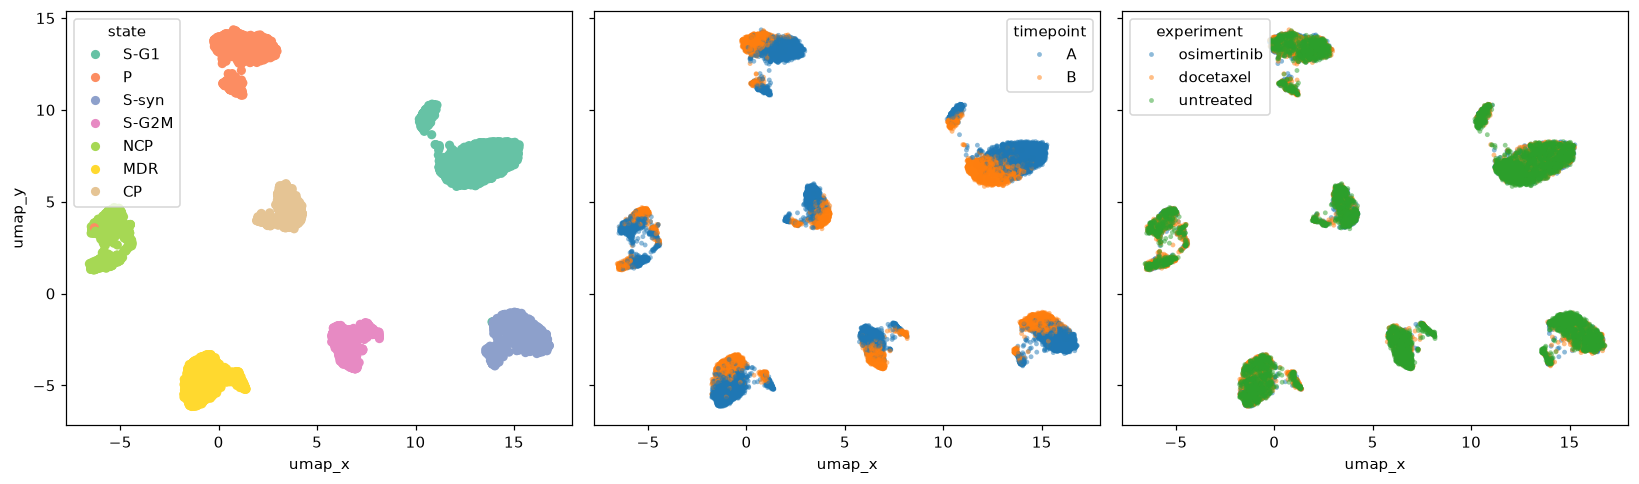

In [5]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [6]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [7]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [8]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [9]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [10]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [11]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

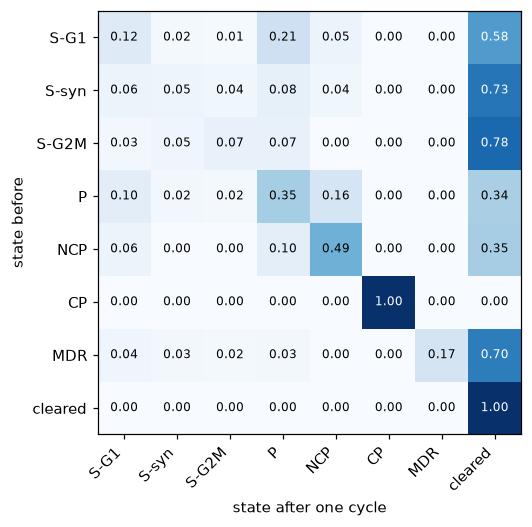

In [12]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

* CP to CP is also an absorbing state. This means that CP cells are resistant to osimertinib.
* None of the other states are high enough to say that they are absorbing.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [13]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [14]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [15]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

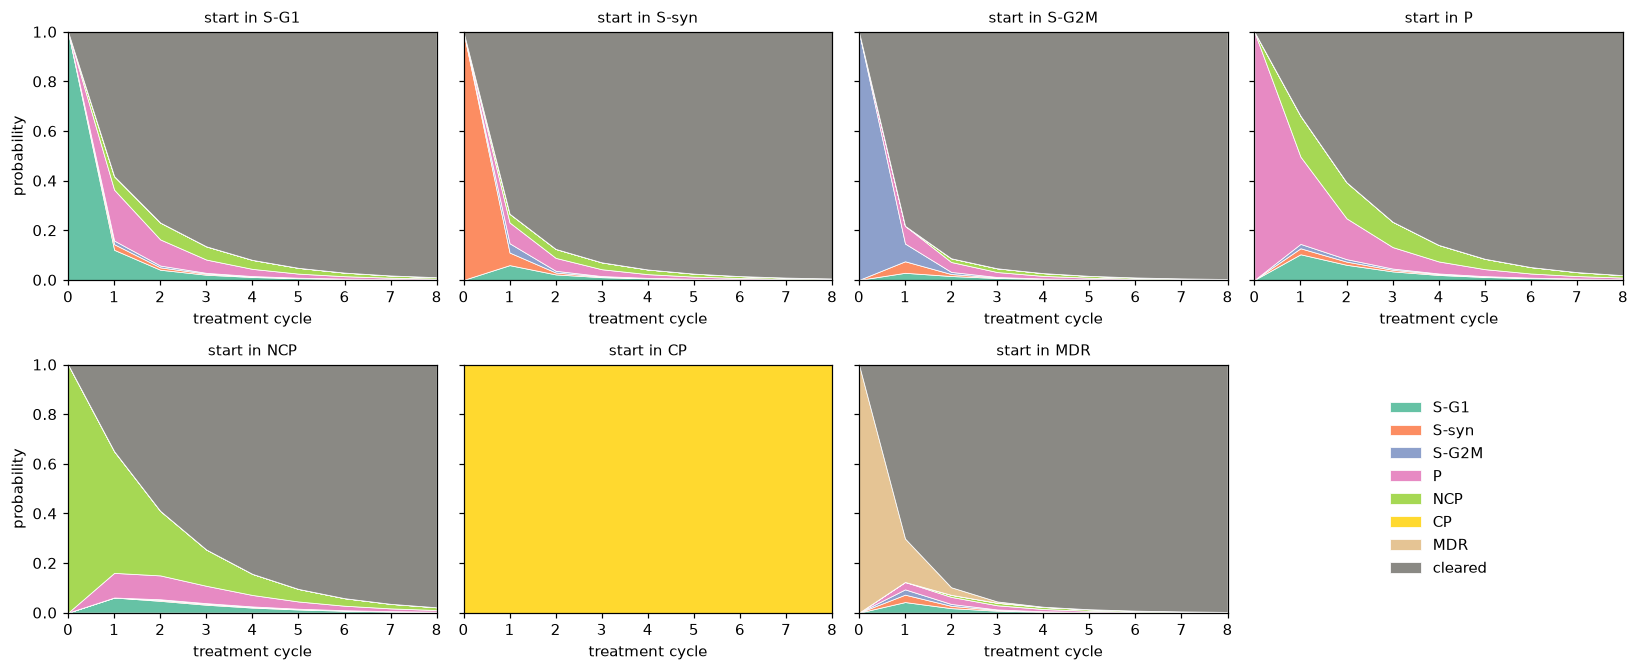

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [16]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

In [17]:
alive8 = {s: 1 - evolve(basis(s, P_hat), P_hat, 8)[-1, -1] for s in OUTCOMES}
threshold = 0.01
for s,v in alive8.items():
    canc_gone = True if v <= 0.01 else False
    print("fraction alive after 8 cycles, starting in", s, ":", round(v, 3), canc_gone)

fraction alive after 8 cycles, starting in S-G1 : 0.011 False
fraction alive after 8 cycles, starting in S-syn : 0.006 True
fraction alive after 8 cycles, starting in S-G2M : 0.004 True
fraction alive after 8 cycles, starting in P : 0.019 False
fraction alive after 8 cycles, starting in NCP : 0.022 False
fraction alive after 8 cycles, starting in CP : 1.0 False
fraction alive after 8 cycles, starting in MDR : 0.003 True
fraction alive after 8 cycles, starting in cleared : 0.0 True


In [18]:
alive_all = pd.DataFrame({'type': alive8.keys(), 'fraction_remaining': alive8.values()})
alive_all

,type,fraction_remaining
0,S-G1,0.010811
1,S-syn,0.005621
2,S-G2M,0.003599
3,P,0.019026
4,NCP,0.021593
5,CP,1.000000
6,MDR,0.002948
7,cleared,0.000000


In [19]:
alive_all = pd.DataFrame()
for i in range(1, 9,1):
    alive = {s: 1 - evolve(basis(s, P_hat), P_hat, i)[-1, -1] for s in OUTCOMES}
    alive_this_round = pd.DataFrame({'starting type': alive.keys(), 'round': i, 'fraction_remaining': alive.values()})
    alive_all = pd.concat([alive_all, alive_this_round])

alive_all.query("fraction_remaining < 0.01").sort_values('round', ascending=False)

,starting type,round,fraction_remaining
1,S-syn,8,0.005621
2,S-G2M,8,0.003599
6,MDR,8,0.002948
7,cleared,8,0.000000
1,S-syn,7,0.009256
2,S-G2M,7,0.005931
6,MDR,7,0.004870
7,cleared,7,0.000000
7,cleared,6,0.000000
2,S-G2M,6,0.009797


<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
    * After 8 cycles, and assuming that a fraction of anything below 0.01 is enough to say the cancer is gone, osimertinib eliminates cancer cells for tumors starting with S-Syn, S-G2M, and MDR. Cancer survives in tumors that started with S-G1, P, NCP, and CP.
- Of the states that can be cleared, which tumor lasts the longest?
    * Assuming that S-Syn, S-G2M, and MDR are the three cleared states: S-Syn is the tumor that is the latest to clear, i.e. it lasts the longest.
- Which starting state sticks around for the most cycles of drug?
    * CP stays around for most cycles of the drug: it does not change.
- Which starting state results in the highest proportion of alive cells after three cycles?
    * CP has the highest proportion of alive cells after three cycles: it does not change from 1.
</div>


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [20]:
OUTCOMES

['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'CP', 'MDR', 'cleared']

In [21]:
# need to pull distribution at timepoint A across ALL experiments
at_A = cells[cells.timepoint == "A"][["lineage_tag", "state"]]

# Need to get them in order so use the reindex on columns of p_hat
# This is a gut check line to make sure it worked.
at_A['state'].value_counts(normalize=True).reindex(OUTCOMES)

state
S-G1       0.247000
S-syn      0.148333
S-G2M      0.099444
P          0.152556
NCP        0.102444
CP         0.097222
MDR        0.153000
cleared         NaN
Name: proportion, dtype: float64

In [22]:
at_A['state'].value_counts()

state
S-G1     2223
MDR      1377
P        1373
S-syn    1335
NCP       922
S-G2M     895
CP        875
Name: count, dtype: int64

[0.247      0.14833333 0.09944444 0.15255556 0.10244444 0.09722222
 0.153      0.        ]


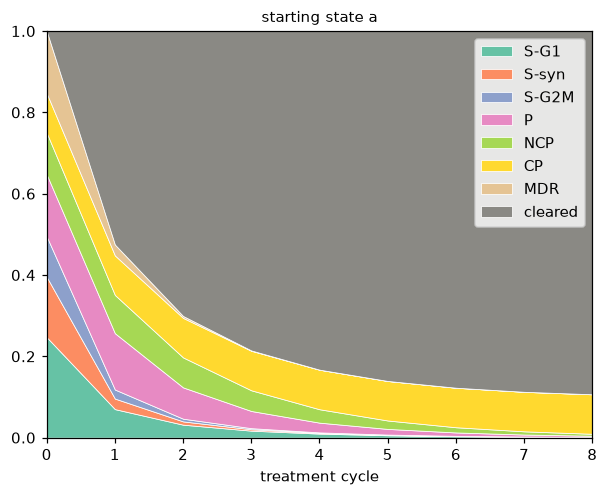

In [23]:
# Your code here
# Leave out cleared since its NAN
names = ['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'CP', 'MDR']
pi_mix = np.array(at_A['state'].value_counts(normalize=True).reindex(names))#: set this equal to the starting vector from timepoint A
# ADD back in a zero for the nan
pi_mix = np.append(pi_mix, 0)
# Gut check that the vector matches the above
print(pi_mix)
# evolve pi_mix and plot the results
n_cycles = 8

a_evolve_osi = evolve(pi_mix, P = P_hat, n_cycles=n_cycles)


t = np.arange(len(a_evolve_osi))
plt.stackplot(t, a_evolve_osi.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()


<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP dominates the remaining cluster. These cells will never be cleared. The osimertinib drug does not work on CP cells. Mathematically, it is an absorbing state.

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [24]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position


P_osi = P_hat.to_numpy()


# MAKE PDOC
doc = cells[cells["experiment"] == "docetaxel"]
at_A = doc[doc.timepoint == "A"][["lineage_tag", "state"]]
at_B = doc[doc.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc_df = counts.div(counts.sum(axis=1), axis=0)
P_doc_df.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc_df.columns})

P_doc = P_doc_df.to_numpy()


# MAKE holiday
holiday = cells[cells["experiment"] == "untreated"]
at_A = holiday[holiday.timepoint == "A"][["lineage_tag", "state"]]
at_B = holiday[holiday.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_holiday_df = counts.div(counts.sum(axis=1), axis=0)
P_holiday_df.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_holiday_df.columns})

P_holiday = P_holiday_df.to_numpy()

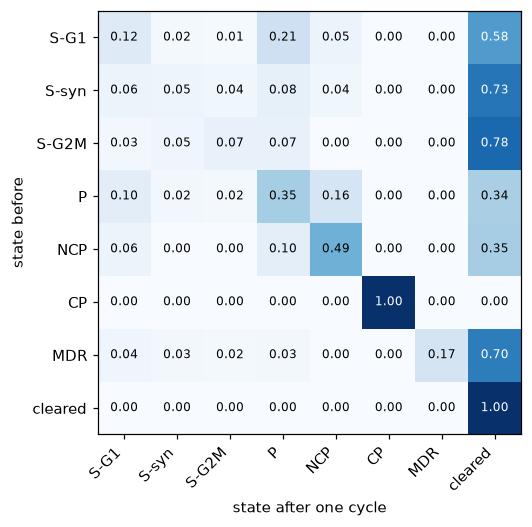

In [25]:
show_matrix(P_hat)

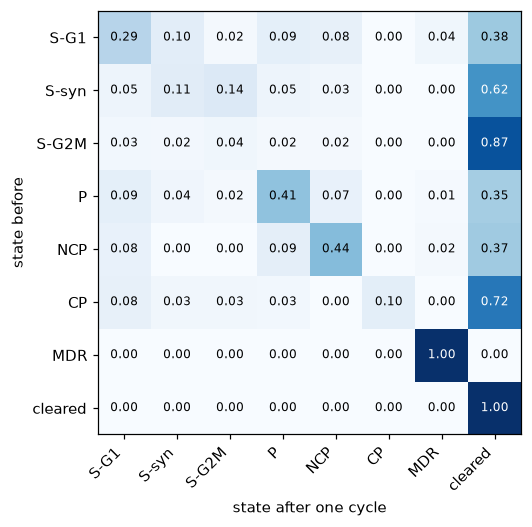

In [26]:
show_matrix(P_doc_df)

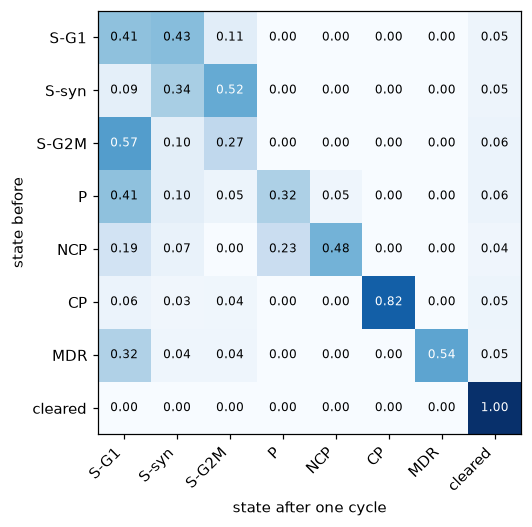

In [27]:
show_matrix(P_holiday_df)

1. Matrices printed above. Notes:
    * Under drug holiday, there appear to be no absorbing states (besides clear -> clear). Transitions along the diagonal seem most common, meaning that cancer cells for people going untreated do not change types very much. Cells rarely transition to cleared, which makes sense because they are going untreated.
    * Under docetaxel, only absorbing state besides clear -> clear is MDR -> MDR. We gain an important insight here: Osimertinib is effective against MDR but not CP, and docetaxel is effective against CP but not MDR.


[0.247      0.14833333 0.09944444 0.15255556 0.10244444 0.09722222
 0.153      0.        ]


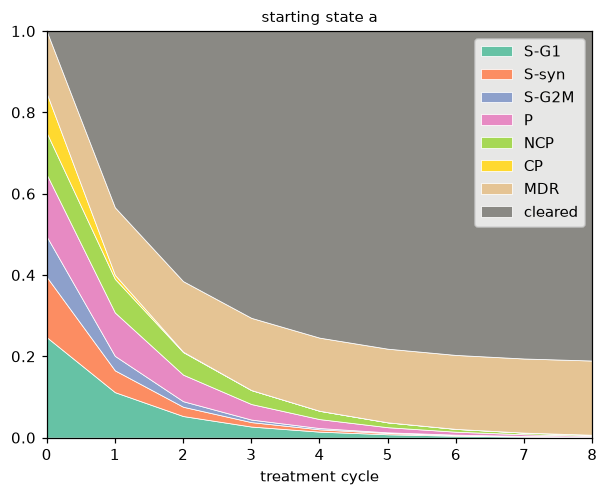

In [28]:
print(pi_mix)
# evolve pi_mix and plot the results
n_cycles = 8

a_evolve_doc = evolve(pi_mix, P = P_doc_df, n_cycles=n_cycles)


t = np.arange(len(a_evolve_doc))
plt.stackplot(t, a_evolve_doc.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()

2. Most types of cancer cell approach cleared OR are absorbed into MDR. The proportion of MDR seems to grow under docetaxel.

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

[0.247      0.14833333 0.09944444 0.15255556 0.10244444 0.09722222
 0.153      0.        ]


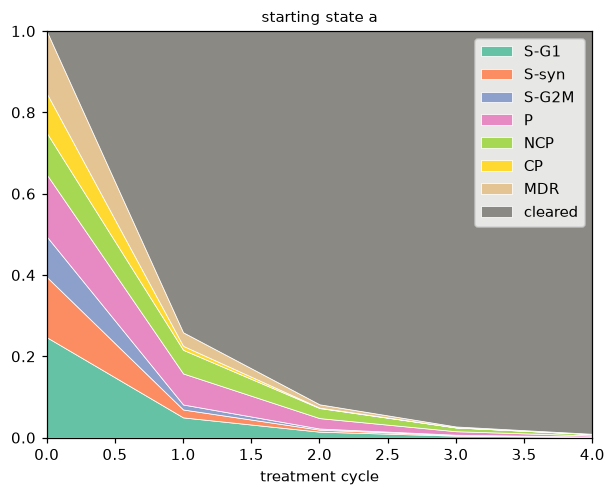

In [29]:
## Add code here
print(pi_mix)
# each evolution now represents two cycles
n_cycles = 4
P_osi_doc = P_hat @ P_doc_df

a_evolve_both = evolve(pi_mix, P = P_osi_doc, n_cycles=n_cycles)


t = np.arange(len(a_evolve_both))
plt.stackplot(t, a_evolve_both.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()

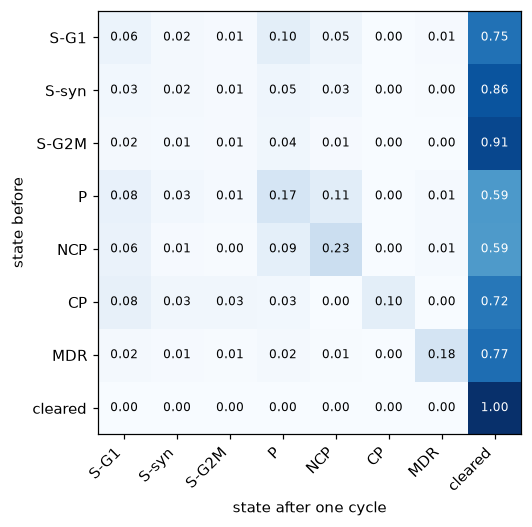

In [30]:
show_matrix(P_osi_doc)

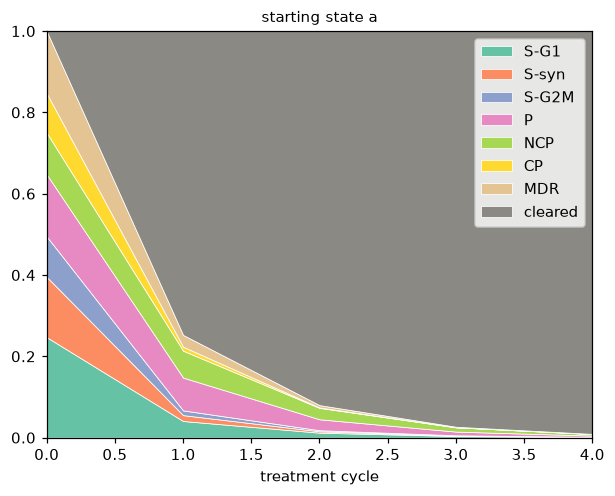

In [31]:
n_cycles = 4
P_doc_osi = P_doc_df @ P_hat

a_evolve_both = evolve(pi_mix, P = P_doc_osi, n_cycles=n_cycles)


t = np.arange(len(a_evolve_both))
plt.stackplot(t, a_evolve_both.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()

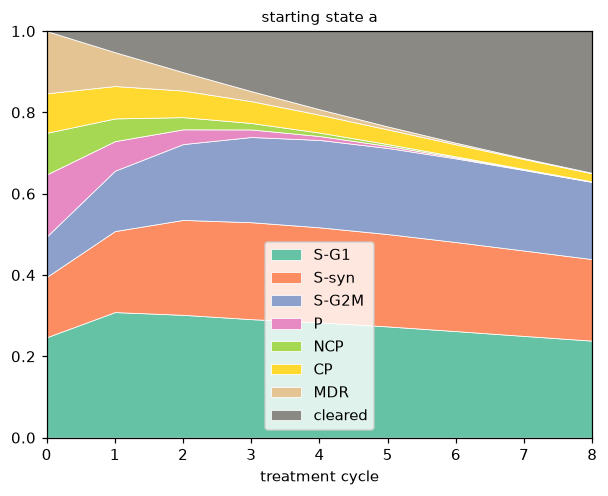

In [32]:
n_cycles = 8

a_evolve_holiday = evolve(pi_mix, P = P_holiday_df, n_cycles=n_cycles)


t = np.arange(len(a_evolve_holiday))
plt.stackplot(t, a_evolve_holiday.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()

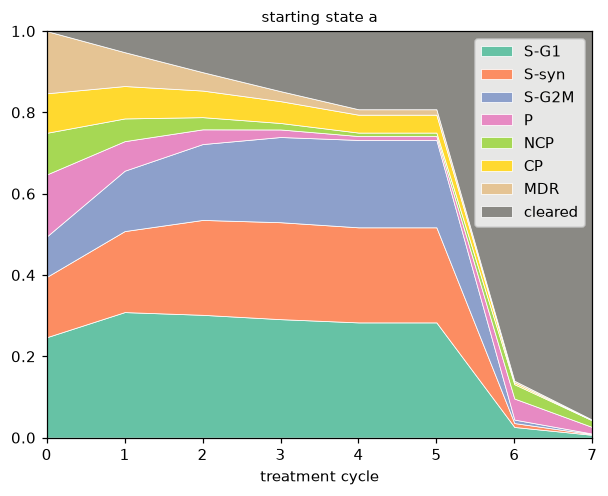

In [33]:
# Strategy 1. Holiday for 4 cycles, then treat with combination for 4 cycles (2 each).
a_evolve_part1 = evolve(pi_mix, P = P_holiday_df, n_cycles=4)
a_evolve_part2 = evolve(a_evolve_part1[-1], P = P_doc_osi, n_cycles = 2)

a_combine = np.concat([a_evolve_part1, a_evolve_part2])

t = np.arange(len(a_combine))
plt.stackplot(t, a_combine.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()


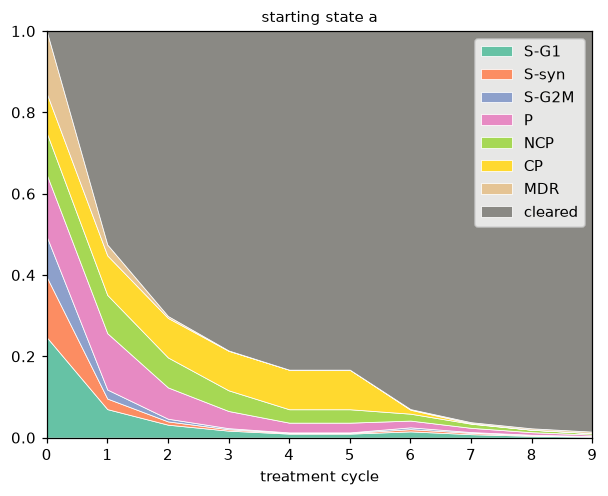

In [34]:
# Strategy 2. 4 osi, 4 doc
a_evolve_4_osi = evolve(pi_mix, P = P_hat, n_cycles=4)
a_evolve_4_doc = evolve(a_evolve_4_osi[-1], P = P_doc_df, n_cycles = 4)

a_combine = np.concat([a_evolve_4_osi, a_evolve_4_doc])

t = np.arange(len(a_combine))
plt.stackplot(t, a_combine.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)

plt.title('starting state a', fontsize=10); plt.xlabel("treatment cycle")
plt.xlim(0, t[-1]); plt.ylim(0, 1)
plt.legend()
plt.show()


1. Compared to eight rounds of osimertinib alone or eight rounds of docetaxel alone, the combination of treatments does a better job of attacking each drugs individual 'weakness' (CP for osi, MDR for doc). This is reinforced when looking at the transition matrix: when using the treatments together, there is no longer an absorbing state besides cleared -> cleared.
2. It does not matter which drug comes first, both reach the same outcome (shown with code above).
3. Looking at the transition matrix for a drug holiday, it seems that the drug resistant varieties (MDR, CP, NCP, P), decrease over time, moving to cleared or a part of one of the less resistant types. So, if a person is not responding to treatment, counterintuitevely it might be a good idea to wait out the resistant varieties before resuming treatment.
4. Two approaches:
    * Do nothing for 4 cycles, then four rounds combined treatment: Results in many less MDR and CP cells from the start of treatment. Doesn't get all the way to cleared in four cycles, but is less 'invasive' and effective to reduce number of resistant cells.
    * 4 rounds of osi, then 4 rounds of doc: Osi effectively cleared out all the MDR, then Doc was able to clean up by clearing out the remaining CP. Still 8 cycles, but similiar effect to alternating.


## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [35]:
rng = np.random.default_rng(100)

In [36]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

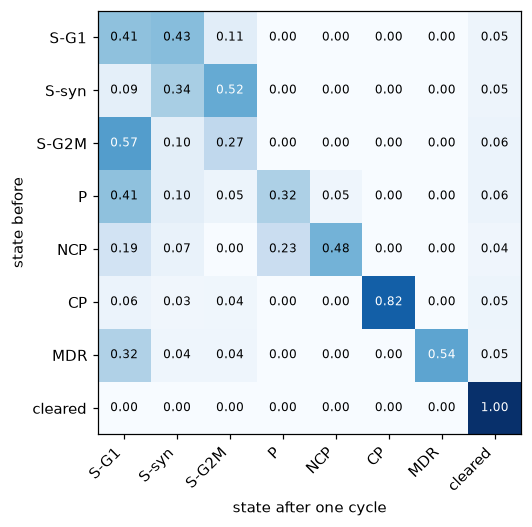

In [37]:
show_matrix(P_holiday_df)

In [38]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

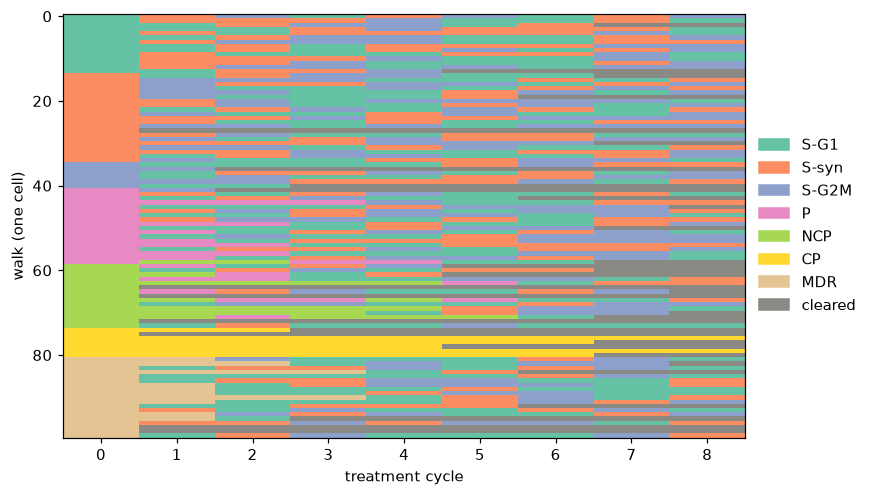

In [39]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [40]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

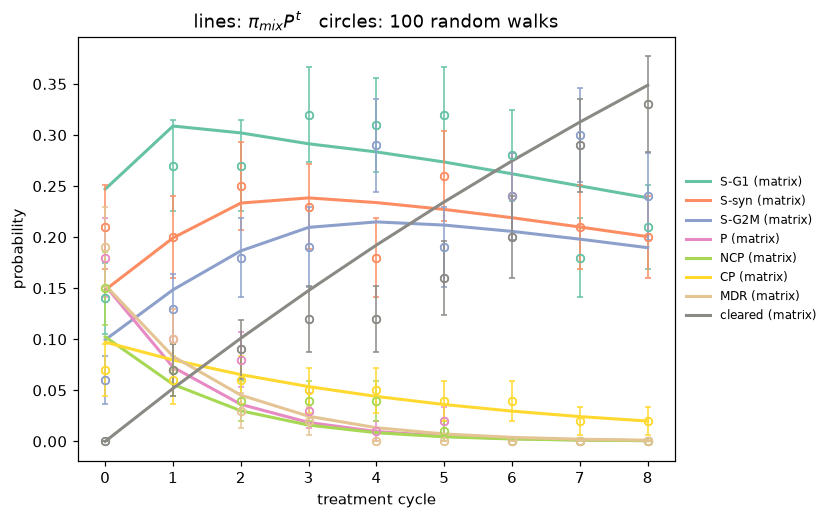

In [41]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

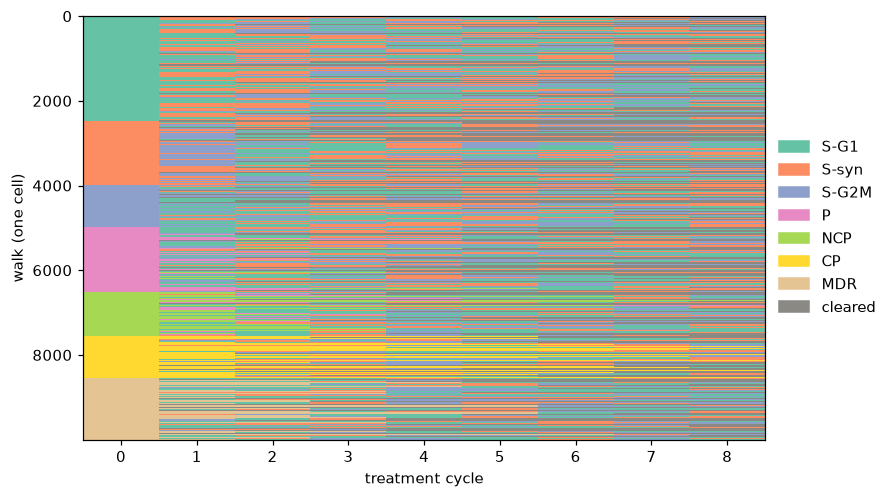

In [42]:
N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [43]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

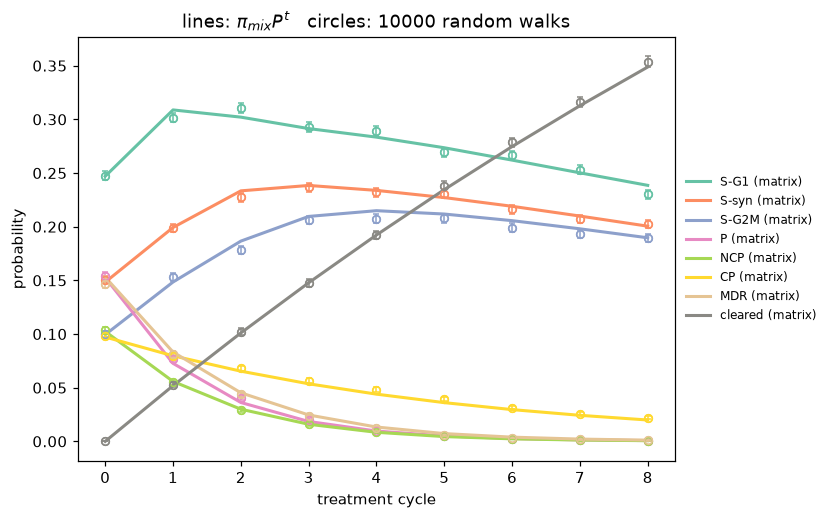

In [44]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

* Rerunning with N_walks set to 10_000, the actual lines do not change that much, but the error bars do. With many more replications, the error becomes smaller because there is less variability in the outcomes. They are more stable.

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [45]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

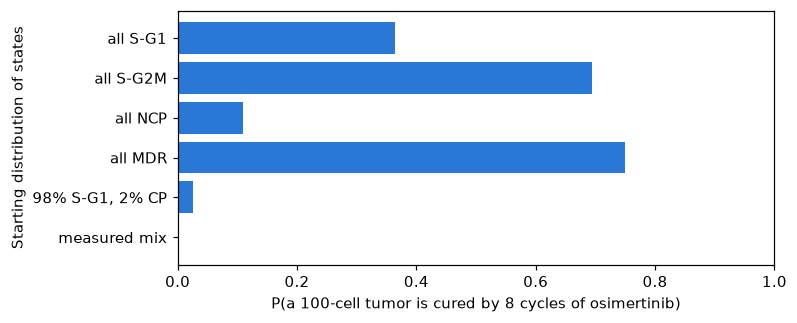

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.365,1.025,0.000
all S-G2M,0.695,0.345,0.000
all NCP,0.110,2.140,0.000
all MDR,0.750,0.275,0.000
"98% S-G1, 2% CP",0.025,3.190,0.638
measured mix,0.000,10.685,0.918


In [46]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

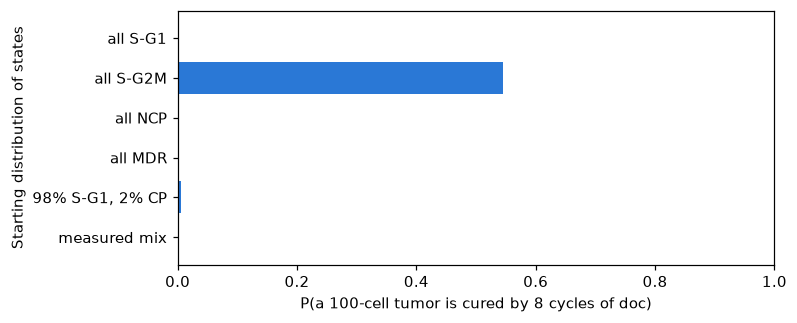

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [47]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of doc)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

* It seems that across the board, doc is less effective at eliminating every cell of a 100 cell tumor. For many of the less resistant varieties, mean surviving cells are low but not gone. The only result with a high probability is all S-G2M for doc at around 0.57.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [48]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])


N_WALKS = 10_000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state


In [49]:
# write a function that runs 1000 random walks and saves them
def random_walks(pi0, P, n_cycles, rng, n_walks=1000):
    starts = rng.choice(len(pi0), size=n_walks, p=pi0)
    walks = []
    for i in range(n_walks):
        walk = random_walk(starts[i], P, n_cycles, rng)
        walks.append(walk)
    return walks
# you will use this function 100 times to generate a simulated set of tumors

tumors_set = []
for i in range(100):
    tumors = random_walks(pi_mix, P_osi, n_cycles=8, rng=rng)
    tumors_set.append(tumors)

    
    
# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells
proportion_resistant = []
persistors = [3,4]
for i in range(len(tumors_set)):
    tally = 0
    for j in range(len(tumors_set[i])):
        walk = tumors_set[i][j]

        for k in range(len(walk)-2):
            if all(state in persistors for state in walk[k:k+3]):
                tally += 1
                break
    proportion_resistant.append(tally/1000)

# repeat for all tumors


# report mean +/- SEM for osimertinib
mean = np.mean(proportion_resistant)
sem = np.std(proportion_resistant) / np.sqrt(100)
print('RESULTS FOR OSI')
print(f'mean resistant{mean}, SEM:{sem}')

# compare to 10% threshold using 95% CI or a hypothesis test
lower_95 = mean - 1.96 * sem
upper_95 = mean + 1.96 * sem
print(f'95% ci": {lower_95}, {upper_95}')



RESULTS FOR OSI
mean resistant0.11574999999999999, SEM:0.000938336293660221
95% ci": 0.11391086086442596, 0.11758913913557402


In [50]:
tumors_set = []
for i in range(100):
    tumors = random_walks(pi_mix, P_doc, n_cycles=8, rng=rng)
    tumors_set.append(tumors)

    
    
# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells
proportion_resistant = []
persistors = [3,4]
for i in range(len(tumors_set)):
    tally = 0
    for j in range(len(tumors_set[i])):
        walk = tumors_set[i][j]

        for k in range(len(walk)-2):
            if all(state in persistors for state in walk[k:k+3]):
                tally += 1
                break
    proportion_resistant.append(tally/1000)

# repeat for all tumors


# report mean +/- SEM
print('results for doc')
mean = np.mean(proportion_resistant)
sem = np.std(proportion_resistant) / np.sqrt(100)
print(f'mean resistant{mean}, SEM:{sem}')

# compare to 10% threshold using 95% CI or a hypothesis test
lower_95 = mean - 1.96 * sem
upper_95 = mean + 1.96 * sem
print(f'95% ci": {lower_95}, {upper_95}')


results for doc
mean resistant0.09074999999999997, SEM:0.0009584753517957569
95% ci": 0.08887138831048029, 0.09262861168951965


In [51]:
tumors_set = []
for i in range(100):
    tumors = random_walks(pi_mix, P_doc @ P_osi, n_cycles=4, rng=rng)
    tumors_set.append(tumors)
 
    
# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells
proportion_resistant = []
persistors = [3,4]
for i in range(len(tumors_set)):
    tally = 0
    for j in range(len(tumors_set[i])):
        walk = tumors_set[i][j]

        for k in range(len(walk)-2):
            if all(state in persistors for state in walk[k:k+3]):
                tally += 1
                break
    proportion_resistant.append(tally/1000)

# repeat for all tumors


# report mean +/- SEM
print('results for combined doc and osi')
mean = np.mean(proportion_resistant)
sem = np.std(proportion_resistant) / np.sqrt(100)
print(f'mean resistant{mean}, SEM:{sem}')

# compare to 10% threshold using 95% CI or a hypothesis test
lower_95 = mean - 1.96 * sem
upper_95 = mean + 1.96 * sem
print(f'95% ci": {lower_95}, {upper_95}')


results for combined doc and osi
mean resistant0.030320000000000003, SEM:0.0005366339534543076
95% ci": 0.02926819745122956, 0.03137180254877044


In [52]:
tumors_set = []
for i in range(100):
    tumors = random_walks(pi_mix, P_doc @ P_holiday, n_cycles=4, rng=rng)
    tumors_set.append(tumors)


    
    
# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells
proportion_resistant = []
persistors = [3,4]
for i in range(len(tumors_set)):
    tally = 0
    for j in range(len(tumors_set[i])):
        walk = tumors_set[i][j]

        for k in range(len(walk)-2):
            if all(state in persistors for state in walk[k:k+3]):
                tally += 1
                break
    proportion_resistant.append(tally/1000)

# repeat for all tumors


# report mean +/- SEM
print('results for aternating doc and holiday')
mean = np.mean(proportion_resistant)
sem = np.std(proportion_resistant) / np.sqrt(100)
print(f'mean resistant{mean}, SEM:{sem}')

# compare to 10% threshold using 95% CI or a hypothesis test
lower_95 = mean - 1.96 * sem
upper_95 = mean + 1.96 * sem
print(f'95% ci": {lower_95}, {upper_95}')

results for aternating doc and holiday
mean resistant0.021, SEM:0.00044249293779675177
95% ci": 0.02013271384191837, 0.021867286158081634


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
    * Above 10% resistant
- Doxetaxel alone
    * About 9% permenantly resistant
- Alternating OD
    * Below, around 3%
- Doxetaxel with drug holiday
    * Below, around 2%

* Results are stable even at higher numbers of cycles
</div>

* results show that it is better to alternate treatments or skip some (i.e. take some breaks) to avoid making cells resistant.